# Spotify Track Popularity: Exploratory Data Analysis

**Question:** what is associated with a track's popularity (0-100)?

Input: `data/processed/spotify_clean.csv`, one row per unique track (28,352 rows), produced by `01_clean_spotify.py`.
Note: this is an *associational* analysis; it does not show what causes popularity.

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

CANDIDATES = [Path("../data/processed/spotify_clean.csv"),
              Path("data/processed/spotify_clean.csv"),
              Path("spotify_clean.csv")]
DATA = next(p for p in CANDIDATES if p.exists())
df = pd.read_csv(DATA, parse_dates=["track_album_release_date"])
print(f"Loaded {DATA}  ->  {df.shape[0]:,} rows x {df.shape[1]} columns")

# charts are also saved as PNGs (for the README) in docs/figures
FIG_DIR = Path("../docs/figures") if DATA.parent.name == "processed" else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
df.head(3)

Loaded ..\data\processed\spotify_clean.csv  ->  28,352 rows x 26 columns


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,release_date_is_approx,release_year,playlist_count
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,0,2019,2
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,0,2019,2
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,0,2019,3


## 1. Data overview

In [18]:
print("Duplicate track_ids:", df.track_id.duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))
print("Genres:", sorted(df.playlist_genre.unique()))
print("Release years:", df.release_year.min(), "to", df.release_year.max())
df["track_popularity"].describe().round(1)

Duplicate track_ids: 0
Missing values: 0
Genres: ['edm', 'latin', 'pop', 'r&b', 'rap', 'rock']
Release years: 1957 to 2020


count    28352.0
mean        39.3
std         23.7
min          0.0
25%         21.0
50%         42.0
75%         58.0
max        100.0
Name: track_popularity, dtype: float64

## 2. How is popularity distributed?

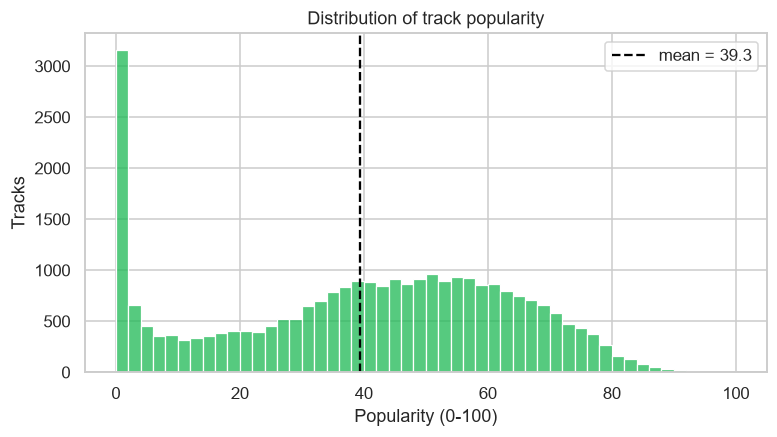

Tracks with popularity 0: 2616


In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df.track_popularity, bins=50, ax=ax, color="#1DB954")
ax.axvline(df.track_popularity.mean(), color="black", ls="--", label=f"mean = {df.track_popularity.mean():.1f}")
ax.set(title="Distribution of track popularity", xlabel="Popularity (0-100)", ylabel="Tracks")
ax.legend()
save("01_popularity_distribution")
plt.show()
print("Tracks with popularity 0:", (df.track_popularity == 0).sum())

Popularity is spread widely, with a spike at 0 (tracks that are effectively unplayed). That spike matters when splitting into quartiles, because many tracks tie at the same value.

## 3. Popularity by genre

,tracks,mean,median
playlist_genre,,,
pop,5132,45.9,50.0
rap,5398,41.8,46.0
latin,4136,41.4,45.0
rock,4305,39.7,44.0
r&b,4504,35.9,38.0
edm,4877,30.7,33.0


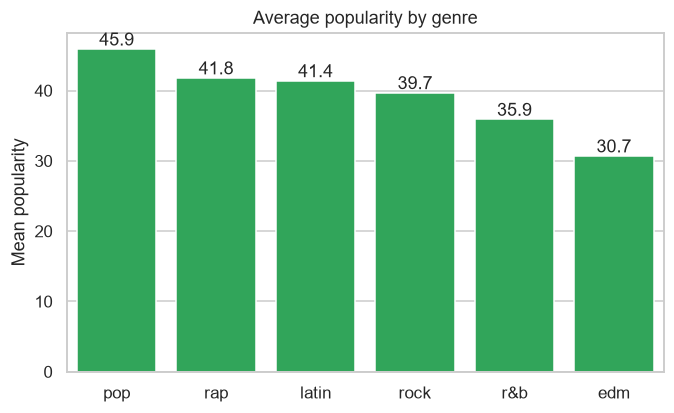

In [20]:
genre = (df.groupby("playlist_genre").track_popularity
           .agg(tracks="count", mean="mean", median="median")
           .round(1).sort_values("mean", ascending=False))
display(genre)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=genre.index, y=genre["mean"], color="#1DB954", ax=ax)
ax.set(title="Average popularity by genre", xlabel="", ylabel="Mean popularity")
for i, v in enumerate(genre["mean"]):
    ax.text(i, v + 0.5, f"{v:.1f}", ha="center")
save("02_popularity_by_genre")
plt.show()

## 4. Playlist reach: tracks on 2+ playlists vs 1 playlist

,tracks,mean,median
playlist_group,,,
1 playlist,25535,37.1,40.0
2+ playlists,2817,59.6,66.0


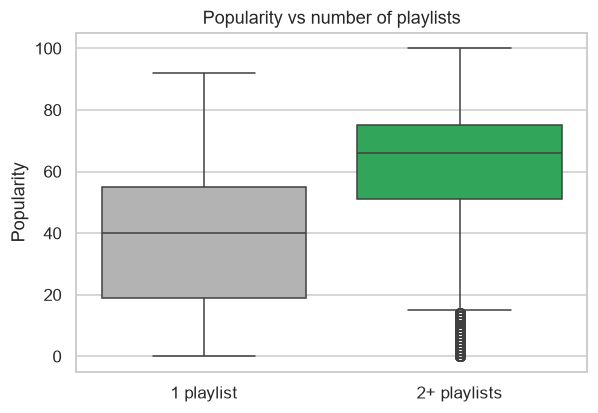

In [21]:
df["playlist_group"] = np.where(df.playlist_count >= 2, "2+ playlists", "1 playlist")
reach = df.groupby("playlist_group").track_popularity.agg(tracks="count", mean="mean", median="median").round(1)
display(reach)

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="playlist_group", y="track_popularity", order=["1 playlist", "2+ playlists"],
            palette={"1 playlist": "#B3B3B3", "2+ playlists": "#1DB954"}, hue="playlist_group", legend=False, ax=ax)
ax.set(title="Popularity vs number of playlists", xlabel="", ylabel="Popularity")
save("03_playlist_reach")
plt.show()

Tracks on 2 or more playlists average about **59.6** popularity versus **37.1** for single-playlist tracks. Direction of cause is unclear: popular tracks may get added to more playlists, and more playlist exposure may also lift popularity.

## 5. Do audio features explain popularity? (Spearman rank correlation)

,spearman_rho
instrumentalness,-0.166
acousticness,0.125
duration_ms,-0.121
energy,-0.110
danceability,0.047
loudness,0.045
liveness,-0.029
valence,0.026
mode,0.018
tempo,-0.010


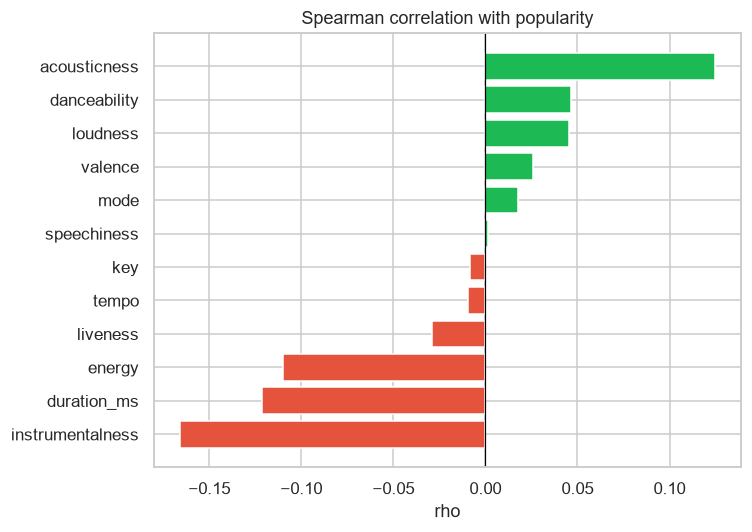

Strongest |rho| = 0.166 (instrumentalness)


In [22]:
features = ["danceability", "energy", "key", "loudness", "mode", "speechiness",
            "acousticness", "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
corr = pd.Series({f: spearmanr(df[f], df.track_popularity)[0] for f in features}).sort_values()
display(corr.round(3).to_frame("spearman_rho").sort_values("spearman_rho", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#1DB954" if v > 0 else "#E5533D" for v in corr]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Spearman correlation with popularity", xlabel="rho")
plt.tight_layout()
save("04_spearman_correlations")
plt.show()
print(f"Strongest |rho| = {corr.abs().max():.3f} ({corr.abs().idxmax()})")

All correlations are weak (strongest is about 0.17, for instrumentalness). Audio features alone are poor predictors of popularity; exposure matters more.

## 6. Popularity over release year

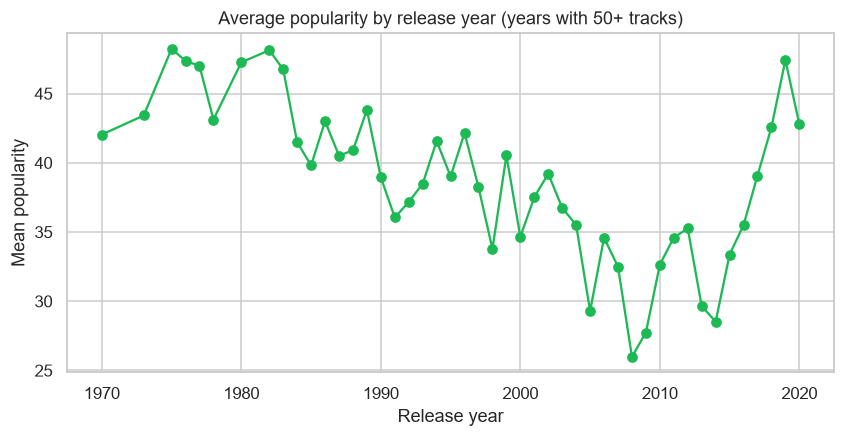

In [23]:
exact = df[df.release_date_is_approx == 0]          # drop year-only (placeholder) dates
yearly = exact.groupby("release_year").track_popularity.agg(tracks="count", mean="mean")
yearly = yearly[yearly.tracks >= 50]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly.index, yearly["mean"], marker="o", color="#1DB954")
ax.set(title="Average popularity by release year (years with 50+ tracks)",
       xlabel="Release year", ylabel="Mean popularity")
save("05_popularity_by_year")
plt.show()

Popularity by release year is **not a simple upward trend**; it is U-shaped. Older tracks that are still on these playlists (1970s-80s) average about 47-48, the low point is around 2008 (about 26), and recent releases climb back to about 47 by 2019.

Possible explanations (not tested here): the older tracks are classics that survived, so they are a selective group; and Spotify's popularity score is weighted toward recent plays, which favours new hits. Year-only release dates are excluded because their month/day is a placeholder.

## 7. Top vs bottom popularity quartile

,track_popularity,playlist_count,danceability,energy,acousticness,instrumentalness
quartile,,,,,,
Q1 (lowest),5.940,1.047,0.643,0.725,0.147,0.121
Q2,33.208,1.035,0.654,0.705,0.172,0.110
Q3,50.196,1.068,0.654,0.684,0.195,0.098
Q4 (highest),67.997,1.399,0.662,0.680,0.196,0.036


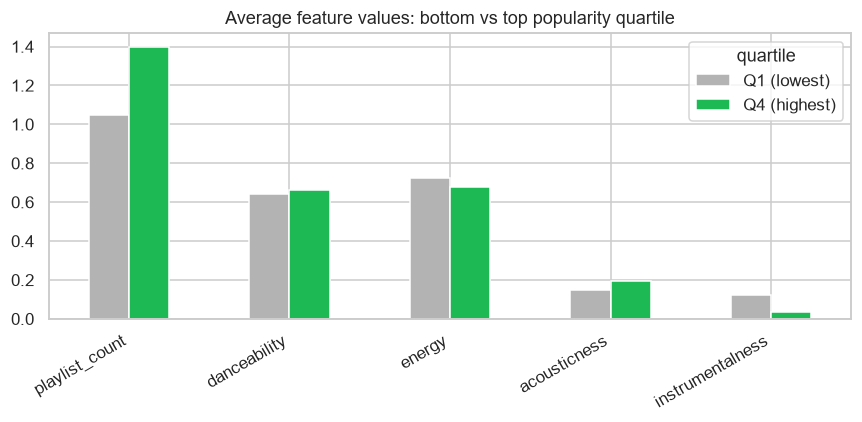

In [24]:
ranked = df.sort_values(["track_popularity", "track_id"]).reset_index(drop=True)
ranked["quartile"] = pd.qcut(np.arange(len(ranked)), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

cols = ["track_popularity", "playlist_count", "danceability", "energy", "acousticness", "instrumentalness"]
quart = ranked.groupby("quartile", observed=True)[cols].mean().round(3)
display(quart)

compare = quart.loc[["Q1 (lowest)", "Q4 (highest)"], cols[1:]].T
compare.plot(kind="bar", figsize=(8, 4), color=["#B3B3B3", "#1DB954"])
plt.title("Average feature values: bottom vs top popularity quartile")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
save("06_quartile_comparison")
plt.show()

## Key findings

1. **Playlist reach is the strongest signal.** Tracks on 2+ playlists average 59.6 popularity vs 37.1 for single-playlist tracks.
2. **Audio features correlate only weakly** with popularity (strongest rank correlation about 0.17).
3. **Genre matters:** pop is highest on average and EDM lowest.
4. **Top-quartile tracks** are on more playlists and are far less instrumental than bottom-quartile tracks.
5. **Release year is U-shaped:** classics (1970s-80s) and recent releases (2017-2019) score highest; the mid-2000s to early 2010s score lowest.

*Caveats: these are associations in one playlist-based dataset, not causal effects. Each track appears once, so its genre is the one from the first playlist row kept during deduplication.*